# Monolayer Ewald Energy Validation

**Goal.** Validate `ezwald`'s monolayer Ewald summation by reproducing, to high precision, the
published static lattice energies of L. Bonsall and A. A. Maradudin,
*"Some static and dynamical properties of a two-dimensional Wigner crystal,"* Phys. Rev. B **15**,
1959–1973 (1977), [doi:10.1103/PhysRevB.15.1959](https://doi.org/10.1103/PhysRevB.15.1959), for
four two-dimensional Bravais lattices: square, primitive rectangular, centered rectangular, and
hexagonal.

**What this tutorial covers:**
- Building a primitive cell and tiling it into a periodic supercell with `ezwald.geometry`
- Computing the per-particle Coulomb energy of a 2D lattice with `ezwald.ewald.Ewald.sum`
- Checking each result against an independent literature reference

**Requirements:** `ezwald`, `numpy`, `jax`, `pandas`, `matplotlib`. Runs in a few seconds on CPU.

## Background

For each lattice, `ezwald` places one electron per primitive cell, tiles the cell into an
$n_x\times n_x$ supercell ($n_x=2$ throughout), and sums the Coulomb interaction with
`ezwald.ewald.Ewald.sum`. Dividing by the number of particles gives the energy per particle.

Bonsall and Maradudin report each lattice's interaction energy as $E_I=-C/\sqrt{a_c}$, where $a_c$
is the area per particle and $C$ is a tabulated, lattice-dependent constant. Because this counts
each pair interaction twice, the ground-state energy per electron is
$\frac{1}{2}E_I=-C/(2\sqrt{a_c})$ (their Eq. 2.13), which is the quantity computed by `ezwald`.
The reference values used below are exactly the paper's own $C$ constants — not fitted or adjusted in any way.

In [1]:
import os
os.environ['JAX_PLATFORMS'] = 'cpu'  # this tutorial is fast enough that a CPU backend is sufficient
import jax
jax.config.update("jax_enable_x64", True)  # match the double precision used throughout ezwald

import numpy as np
import jax.numpy as jnp
import pandas as pd
import matplotlib.pyplot as plt
from ezwald import ewald, geometry as geo

np.set_printoptions(precision=6, suppress=True)
print(f"jax {jax.__version__}, numpy {np.__version__}, pandas {pd.__version__}")

jax 0.5.0, numpy 2.2.2, pandas 3.0.6


## 1. Square lattice

Primitive cell: unit square lattice. Reference: Bonsall & Maradudin, Eq. (2.17),
$C=3.900265$.

In [2]:
def energy_square(nx=2):
    # Primitive cell: square lattice
    axes_primitive = np.eye(2)

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.17): C = 3.900265
    ac = geo.calc_volume(axes_primitive)
    expected = -3.900265 / (2 * ac ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle

_ = energy_square()

ezwald = -1.950132   Bonsall & Maradudin = -1.950133   |difference| = 2.39e-08


## 2. Primitive rectangular lattice

Primitive cell: rectangular lattice, aspect ratio $\lambda=a_1/a_2=0.95$ (the value used by the
paper as a worked example). Reference: Bonsall & Maradudin, Eq. (2.20), $C=3.898597$.

In [3]:
def energy_primitive_rectangle(nx=2):
    # Primitive cell: rectangular lattice (aspect ratio lambda < 1)
    lam = 0.95
    a2 = 1.0
    a1 = lam * a2
    axes_primitive = np.diag([a1, a2])

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.20): C = 3.898597
    expected = -3.898597 / (2 * (a1 * a2) ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle

_ = energy_primitive_rectangle()

ezwald = -1.999938   Bonsall & Maradudin = -1.999938   |difference| = 3.03e-07


## 3. Centered rectangular lattice

Primitive cell: centered rectangular lattice, aspect ratio $\lambda=0.95$. Reference:
Bonsall & Maradudin, Eq. (2.22), $C=3.900647$.

In [4]:
def energy_centered_rectangle(nx=2):
    # Primitive cell: centered rectangular lattice (aspect ratio lambda < 1)
    lam = 0.95
    a2 = 1.0
    a1 = lam * a2
    axes_primitive = np.array([
        [a1,     0.0],
        [a1 / 2, a2 / 2]
    ])

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.22): C = 3.900647
    ac = geo.calc_volume(axes_primitive)
    expected = -3.900647 / (2 * ac ** 0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle

_ = energy_centered_rectangle()

ezwald = -2.829828   Bonsall & Maradudin = -2.829827   |difference| = 7.60e-07


## 4. Hexagonal lattice

Primitive cell: hexagonal (triangular) lattice. Reference: Bonsall & Maradudin,
Eq. (2.18), $C=3.921034$ — the largest $C$ of the four lattices considered here, consistent with
the paper's identification of the hexagonal lattice as the two-dimensional Wigner crystal ground
state.

In [5]:
def energy_hexagonal(nx=2):
    # Primitive cell: hexagonal (triangular) lattice
    axes_primitive = np.array([
        [1.0, 0.0],
        [-0.5, np.sqrt(3) / 2]
    ])

    # Supercell axes (scaled)
    axes = nx * axes_primitive

    # Generate grid of lattice sites for the supercell
    latvec = axes / np.array((nx, nx))[:, None]
    pos = geo.gen_lattice(latvec, (nx, nx), kspace=False)

    # Build Ewald sum objects
    ew, rvecs, kvecs = ewald.make_ewald(axes)
    charge = -jnp.ones(len(pos))
    total_energy = ew.sum(pos, charge, rvecs, kvecs)
    energy_per_particle = total_energy / nx**2

    # Reference value from Bonsall & Maradudin (1977), Eq. (2.18): C = 3.921034
    ac = geo.calc_volume(axes_primitive)
    expected = -3.921034 / (2 * ac**0.5)

    print(f"ezwald = {energy_per_particle:.6f}   Bonsall & Maradudin = {expected:.6f}   "
          f"|difference| = {abs(energy_per_particle - expected):.2e}")
    assert np.isclose(energy_per_particle, expected, rtol=0, atol=2e-6)
    return energy_per_particle

_ = energy_hexagonal()

ezwald = -2.106711   Bonsall & Maradudin = -2.106713   |difference| = 1.29e-06


## 5. Summary

The table below compares the energy per particle computed by `ezwald` against the result
reported by Bonsall and Maradudin (1977) for each of the four lattices considered.

ezwald = -1.950132   Bonsall & Maradudin = -1.950133   |difference| = 2.39e-08
ezwald = -1.999938   Bonsall & Maradudin = -1.999938   |difference| = 3.03e-07
ezwald = -2.829828   Bonsall & Maradudin = -2.829827   |difference| = 7.60e-07
ezwald = -2.106711   Bonsall & Maradudin = -2.106713   |difference| = 1.29e-06


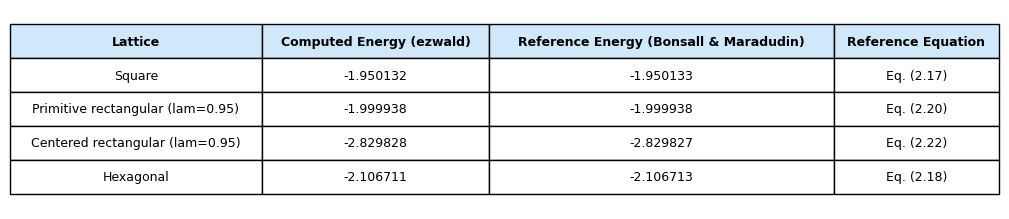

In [6]:
E_square = energy_square()
E_prim_rect = energy_primitive_rectangle()
E_cent_rect = energy_centered_rectangle()
E_hex = energy_hexagonal()

ac_square = geo.calc_volume(np.eye(2))
ac_prim_rect = 0.95 * 1.0
ac_cent_rect = geo.calc_volume(np.array([[0.95, 0.0], [0.95 / 2, 0.5]]))
ac_hex = geo.calc_volume(np.array([[1.0, 0.0], [-0.5, np.sqrt(3) / 2]]))

rows = [
    ("Square",                          E_square,     3.900265, ac_square,     "Eq. (2.17)"),
    ("Primitive rectangular (lam=0.95)", E_prim_rect,  3.898597, ac_prim_rect,  "Eq. (2.20)"),
    ("Centered rectangular (lam=0.95)",  E_cent_rect,  3.900647, ac_cent_rect,  "Eq. (2.22)"),
    ("Hexagonal",                       E_hex,        3.921034, ac_hex,        "Eq. (2.18)"),
]

table = pd.DataFrame(
    [
        {
            "Lattice": name,
            "Computed Energy (ezwald)": float(E),
            "Reference Energy (Bonsall & Maradudin)": -C / (2 * ac ** 0.5),
            "Reference Equation": eq,
        }
        for name, E, C, ac, eq in rows
    ]
).set_index("Lattice")

# Rendered as a matplotlib figure rather than a pandas Styler/HTML table. "Lattice" is kept as an
# ordinary first column (not matplotlib's separate rowLabels), so its header sits in the same
# row as "Computed Energy (ezwald)" instead of leaving that corner cell blank.
col_labels = ["Lattice"] + list(table.columns)
cell_text = [
    [name, f"{row['Computed Energy (ezwald)']:.6f}",
     f"{row['Reference Energy (Bonsall & Maradudin)']:.6f}", row['Reference Equation']]
    for name, row in table.iterrows()
]

fig, ax = plt.subplots(figsize=(9.0, 0.5 + 0.45 * len(cell_text)))
ax.axis("off")

mpl_table = ax.table(cellText=cell_text, colLabels=col_labels,
                      cellLoc="center", loc="center")
mpl_table.auto_set_font_size(False)
mpl_table.set_fontsize(9)
mpl_table.auto_set_column_width(col=list(range(len(col_labels))))
mpl_table.scale(1, 1.8)

for (row, col), cell in mpl_table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="bold")
        cell.set_facecolor("#cfe8fa")

fig.tight_layout()

## Conclusion

All four lattices agree with Bonsall and Maradudin's published energies to within $2\times10^{-6}$,
confirming that `ezwald`'s monolayer Ewald summation reproduces the known static Coulomb energy of
a two-dimensional Wigner crystal.